In [1]:
%pylab inline

import smatch
import treecorr
from astropy.table import Table, vstack
import astropy.io.fits as pyfits
import astropy.io.ascii as ascii
import catSelect

Populating the interactive namespace from numpy and matplotlib


In [2]:
cd wrkDir/

/work/xiangchong.li/work/S18ASimHSC


# Difference between S16A, S18A and S19A

## Bright Star Catalog I (ICGs)
We use the Isolate Central Galaxies from SDSS Main sample (Wang et. al), and divided them into four i-band magnitude bins

In [42]:
cutlist=[]
minlist =   [10,14.5,15.5,16.5]
maxlist =   [14.5,15.5,16.5,17.5]

cutlist.extend(minlist)
cutlist.extend(maxlist)
cutlist=np.unique(cutlist)
bsAname =   'database/Wang_S16A.csv'
bsCat   =   Table.read(bsAname)
bsCat['coord_ra'].name='ra'
bsCat['coord_dec'].name='dec'
bsCat['imag_model'].name='mag'
fdfcMask=catSelect.getFDFCS16(bsCat['ra'],bsCat['dec'])
bsCat=bsCat[fdfcMask]

bhcat=pyfits.getdata('./database/compare/scat-s18.fits')
bhcat=bhcat[bhcat['mag']<18.]
area=108.

NSIDE = 2048
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:17: RuntimeWarning: invalid value encountered in less


Text(0.5, 1.0, 'Spacial Distribution of ICGs')

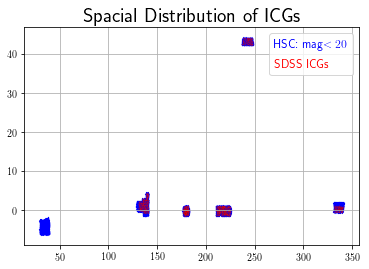

In [5]:
plt.scatter(bhcat['ra'],bhcat['dec'],s=0.001,c='blue',label=r'HSC: mag$<20$')
plt.scatter(bsCat['ra'],bsCat['dec'],s=0.001,c='red',label='SDSS ICGs')
leg=plt.legend(fontsize=12.,handletextpad=0.,handlelength=0.,markerscale=0.)

leg.legendHandles[0].set_visible(False)
leg.texts[0].set_color('blue')
leg.legendHandles[1].set_visible(False)
leg.texts[1].set_color('red')
plt.grid()

plt.title('Spacial Distribution of ICGs',fontsize=20)

Number Density of Bright galaxies
Bin 0:
    Density: 0.0003 /arcmin^2
    Total Number: 106 
Bin 1:
    Density: 0.0008 /arcmin^2
    Total Number: 315 
Bin 2:
    Density: 0.0032 /arcmin^2
    Total Number: 1228 
Bin 3:
    Density: 0.0062 /arcmin^2
    Total Number: 2384 
All:
    Density: 0.0104 /arcmin^2
    Total Number: 4036 


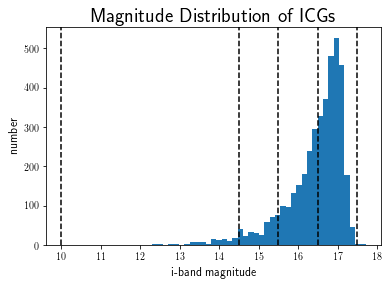

In [95]:
hist,grid,fig=plt.hist(bsCat['mag'],40)
for ic in cutlist:
    axvline(ic,c='black',ls='--')
plt.ylabel('number',fontsize=12)
plt.xlabel('i-band magnitude',fontsize=12)
plt.title('Magnitude Distribution of ICGs', fontsize=20)

print('Number Density of Bright galaxies')
for i in range(len(cutlist)-1):
    mask = (bsCat['mag']>cutlist[i])&(bsCat['mag']<cutlist[i+1])
    num=np.sum(mask)
    print('Bin %d:' %i)
    print('    Density: %.4f /arcmin^2' %(num/area))
    print('    Total Number: %d ' %(num))
num=len(bsCat)
print('All:')
print('    Density: %.4f /arcmin^2' %(num/area))
print('    Total Number: %d ' %(num))

Text(0.5, 1.0, 'Redshift Distribution of ICGs')

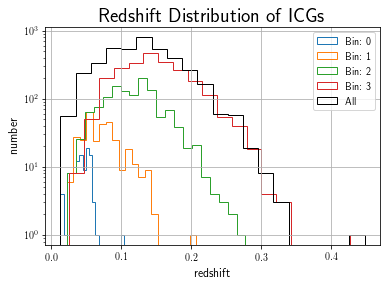

In [82]:
for i in range(len(cutlist)-1):
    mask = (bsCat['mag']>cutlist[i])&(bsCat['mag']<cutlist[i+1])
    hist,grid,fig=plt.hist(bsCat[mask]['z_cl'],20,histtype='step',label='Bin: %d' %(i))
    
hist,grid,fig=plt.hist(bsCat['z_cl'],20,histtype='step',label='all',color='black')
plt.ylabel('number',fontsize=12)
plt.xlabel('redshift',fontsize=12)
plt.yscale('log')
plt.legend()
plt.grid()
plt.title('Redshift Distribution of ICGs', fontsize=20)

### Difference in Magnitude Measurement

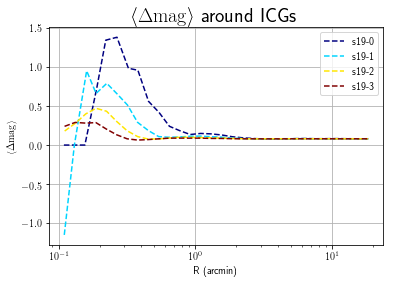

In [32]:
colors = plt.cm.jet(np.linspace(0,1,4))
for ig in range(4):
    #d18=ascii.read('s18-2/plot/galCor/cor2PNK-wl2-Wang-mag-mag-g%s-s18.csv' %ig)
    #plt.plot(d18['meanR'],d18['kappa'],label='s18-%s' %(ig), color=colors[ig], ls='-')
    d19=ascii.read('s18-2/plot/galCor/cor2PNK-wl2-Wang-mag-mag-g%s-s19.csv' %ig)
    plt.plot(d19['meanR'],d19['kappa'],label='s19-%s' %(ig), color=colors[ig], ls='--')

plt.xlabel('R (arcmin)')
plt.ylabel(r'$\langle\Delta \rm{mag}\rangle$')
plt.xscale('log')
plt.title(r'$\langle\Delta \rm{mag}\rangle$ around ICGs',fontsize=20)

plt.grid()
plt.legend(loc='upper right')

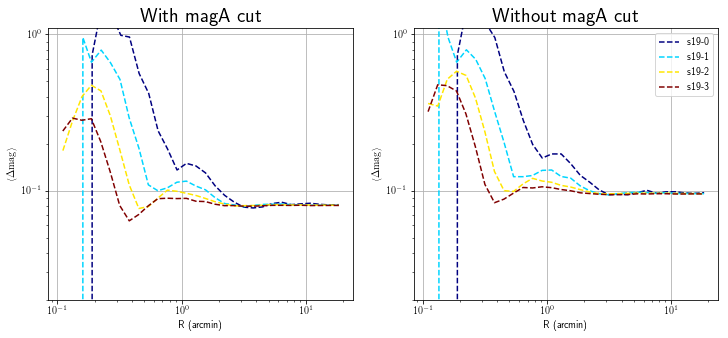

In [14]:
colors = plt.cm.jet(np.linspace(0,1,4))
fig=plt.figure(figsize=(12,5))
ax=fig.add_subplot(1,2,1)
for ig in range(4):
    #d18=ascii.read('s18-2/plot/galCor/cor2PNK-wl2-Wang-mag-mag-g%s-s18.csv' %ig)
    #plt.plot(d18['meanR'],d18['kappa'],label='s18-%s' %(ig), color=colors[ig], ls='-')
    d19=ascii.read('s18-2/plot/galCor/cor2PNK-wl2-Wang-mag-mag-g%s-s19.csv' %ig)
    ax.plot(d19['meanR'],d19['kappa'],label='s19-%s' %(ig), color=colors[ig], ls='--')
ax.set_xlabel('R (arcmin)')
ax.set_ylabel(r'$\langle\Delta \rm{mag}\rangle$')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(0.02,1.1)
ax.set_title(r'With magA cut',fontsize=20)
plt.grid()

ax=fig.add_subplot(1,2,2)
for ig in range(4):
    #d18=ascii.read('s18-2/plot/galCor/cor2PNK-wl2-Wang-mag-mag-g%s-s18.csv' %ig)
    #plt.plot(d18['meanR'],d18['kappa'],label='s18-%s' %(ig), color=colors[ig], ls='-')
    d19=ascii.read('s18-2/plot/galCor/cor2PNK-wl-Wang-mag-mag-g%s-s19.csv' %ig)
    ax.plot(d19['meanR'],d19['kappa'],label='s19-%s' %(ig), color=colors[ig], ls='--')
ax.set_xlabel('R (arcmin)')
ax.set_ylabel(r'$\langle\Delta \rm{mag}\rangle$')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(0.02,1.1)
ax.set_title(r'Without magA cut',fontsize=20)

plt.grid()
plt.legend(loc='upper right')

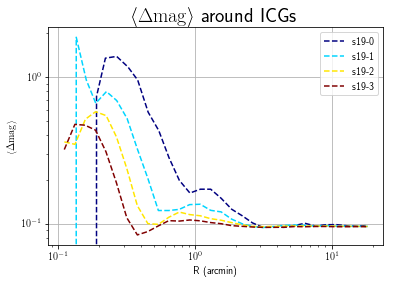

In [6]:

plt.xlabel('R (arcmin)')
plt.ylabel(r'$\langle\Delta \rm{mag}\rangle$')
plt.xscale('log')
plt.yscale('log')
plt.title(r'$\langle\Delta \rm{mag}\rangle$ around ICGs',fontsize=20)

plt.grid()
plt.legend(loc='upper right')

## Merge 3 catalogs
+ HSC bright galaxies (blue)
+ SDSS ICGS (red)
+ GAIA Stars (green)

In [24]:
gaiacat=pyfits.getdata('database/GAIA_Stars.fits',ext=1)
gaiacat=gaiacat[catSelect.getFDFCS16(gaiacat['ra'],gaiacat['dec'])]

NSIDE = 2048
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


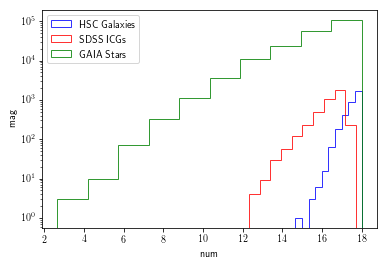

In [63]:
plt.hist(bhcat['mag'],color='blue',histtype='step',alpha=0.8,label='HSC Galaxies')
plt.hist(bsCat['mag'],color='red',histtype='step',alpha=0.8,label='SDSS ICGs')
plt.hist(gaiacat['G_Gaia'],color='green',histtype='step',alpha=0.8,label='GAIA Stars')
plt.legend(loc='upper left')
plt.xlabel('num')
plt.ylabel('mag')
plt.yscale('log')

Text(0.5, 1.0, 'Spacial Distribution of ICGs')

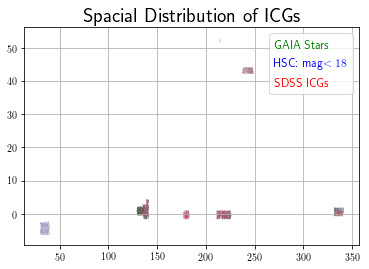

In [91]:
plt.scatter(gaiacat['ra'][::4],gaiacat['dec'][::4],s=1.e-4,alpha=0.2,c='green',label='GAIA Stars')
plt.scatter(bhcat['ra'],bhcat['dec'],s=1.e-4,c='blue',alpha=0.5,label=r'HSC: mag$<18$')
plt.scatter(bsCat['ra'],bsCat['dec'],s=1.e-4,c='red',alpha=0.8,label='SDSS ICGs')
leg=plt.legend(fontsize=12.,handletextpad=0.,handlelength=0.,markerscale=0.)

leg.legendHandles[0].set_visible(False)
leg.texts[0].set_color('green')
leg.legendHandles[1].set_visible(False)
leg.texts[1].set_color('blue')
leg.legendHandles[2].set_visible(False)
leg.texts[2].set_color('red')
plt.grid()

plt.title('Spacial Distribution of ICGs',fontsize=20)

### remove repeated galaxies

In [107]:
match   =   smatch.match(bhcat['ra'],bhcat['dec'],1./3600.,\
    bsCat['ra'],bsCat['dec'],maxmatch=1)
maskbs=np.ones(len(bsCat),dtype=bool)
maskbs[match['i2']]=False
print(len(bsCat))
bsCat=bsCat[maskbs]
print(len(bsCat))

4036
3930


### make merged catalog

In [109]:
raAll=[]
raAll.extend(bsCat['ra'].data)
raAll.extend(bhcat['ra'])
raAll.extend(gaiacat['ra'])
decAll=[]
decAll.extend(bsCat['dec'].data)
decAll.extend(bhcat['dec'])
decAll.extend(gaiacat['dec'])
magAll=[]
magAll.extend(bsCat['mag'].data)
magAll.extend(bhcat['mag'])
magAll.extend(gaiacat['G_Gaia'])
typeAll=[]
typeAll.extend(['ICG']*len(bsCat))
typeAll.extend(['HSC']*len(bhcat))
typeAll.extend(['GAIA']*len(gaiacat))
brightObjCat=Table()
brightObjCat['ra']=raAll
brightObjCat['dec']=decAll
brightObjCat['mag']=magAll
brightObjCat['type']=typeAll
brightObjCat.write('./database/brightObjs-202003292146.fits')

## Match the brightObject catalog to the s18,s19 catalog and determine the minimal distance for each galaxies of s18 and s19

In [3]:
brightObjCat=pyfits.getdata('./database/brightObjs-202003292146.fits')
brightObjCat=brightObjCat[brightObjCat['mag']<17.5]
if not os.path.isfile('database/compare/match-s19-202003292146.fits'):
    matcat19=Table.read('database/compare/match-s19.fits')
    dmag19=matcat19['mag16']-matcat19['mag']
    mask=np.absolute(dmag19)<100.
    matcat19=matcat19[mask]
    match19 =   smatch.match(brightObjCat['ra'],brightObjCat['dec'],25./60.,\
        matcat19['ra'],matcat19['dec'],maxmatch=1,nside=512)
    minDis=np.ones(len(matcat19))*25. # [arcmin]
    minDis[match19['i2']]=np.arccos(match19['cosdist'])*180./np.pi*60.
    matcat19['minDis']=minDis
    matcat19.write('database/compare/match-s19-202003292146.fits')
else:
    matcat19=pyfits.getdata('database/compare/match-s19-202003292146.fits')
matcat19=matcat19[matcat19['ra']>100]

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/astropy/table/column.py:991: RuntimeWarning: invalid value encountered in less
  result = getattr(super(), op)(other)


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/astropy/table/column.py:991: RuntimeWarning: invalid value encountered in less
  result = getattr(super(), op)(other)


Text(0, 0.5, '$\\Delta$ mag')

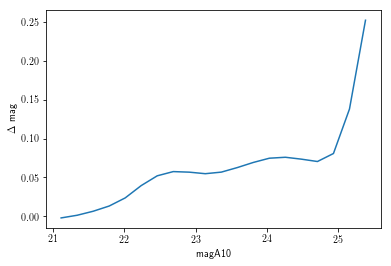

In [32]:
mask1=  (matcat19['mag']<24.5) \
        &(matcat19['res']>0.3) \
        &(matcat19['absE']<2.) \
        &(matcat19['logb']<-0.38) \
        &(matcat19['snr']>10.)
mask2=mask1&(matcat19['magA10']<25.5)
dmag=matcat19['mag16']-matcat19['mag']

dmagHist=np.histogram(matcat19['magA10'][mask2],bins=20,weights=dmag[mask2],range=(21,25.5))[0]
numHist,binHist=np.histogram(matcat19['magA10'][mask2],bins=20,range=(21,25.5))
dmagAve=dmagHist/numHist
plt.plot((binHist[:-1]+binHist[1:])/2.,dmagAve)
plt.xlabel('magA10')
plt.ylabel(r'$\Delta$ mag')